# Week 2: California Housing, Multiple Linear Regression
Goal: vectorized gradient descent with z-score scaling and one engineered feature, compared against sklearn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
data=fetch_california_housing(as_frame=True)
df=data.frame
print(df.shape)
df.head()


(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="MedHouseVal").values
y = df["MedHouseVal"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)


(16512, 8) (4128, 8)
(16512,) (4128,)


Population and AveOccup have the largest scale differences and the biggest outliers. AveRooms and AveBedrms also have suspicious maximums.

In [4]:
mu=X_train.mean(axis=0)
sigma=X_train.std(axis=0)
X_train_s=(X_train-mu)/sigma
X_test_s = (X_test - mu) / sigma


In [5]:
print(X_train_s.mean(axis=0).round(3))
print(X_train_s.std(axis=0).round(3))
print(X_test_s.mean(axis=0).round(3))

[-0. -0.  0. -0. -0. -0.  0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1.]
[-0.026  0.012 -0.013 -0.    -0.004 -0.011 -0.026  0.031]


In [6]:
def compute_cost(X,y,w,b):
    m = X.shape[0]
    err = X @ w + b - y
    cost = (err ** 2).sum() / (2 * m)
    return cost
w0 = np.zeros(X_train_s.shape[1])
b0 = 0.0
print(compute_cost(X_train_s, y_train, w0, b0))

2.8148711615515656


In [7]:
def compute_gradient(X, y, w, b):
    m = X.shape[0]
    err = X @ w + b - y
    dj_dw = X.T @ err / m
    dj_db = err.sum() / m
    return dj_dw, dj_db

dw, db = compute_gradient(X_train_s, y_train, w0, b0)
print(dw)
print(db)
print(dw.shape)

[-0.79851956 -0.11990434 -0.18323882  0.05937156  0.03009842  0.02547085
  0.1653161   0.05358817]
-2.071946937378876
(8,)


In [9]:
def gradient_descent(X,y,w,b,alpha,iters):
    history=[]
    for i in range(iters):
        dw,db=compute_gradient(X,y,w,b)
        w=w-alpha*dw
        b=b-alpha*db
        history.append(compute_cost(X,y,w,b))
    return w,b,history
w,b,history=gradient_descent(X_train_s,y_train,w0,b0,alpha=0.1,iters=1000)
print("start cost:", history[0])
print("end cost:  ", history[-1])
print("weights:", w.round(3))
print("bias:", round(b, 3))

start cost: 2.338860335317682
end cost:   0.2589670605795971
weights: [ 0.855  0.123 -0.296  0.341 -0.002 -0.041 -0.894 -0.867]
bias: 2.072


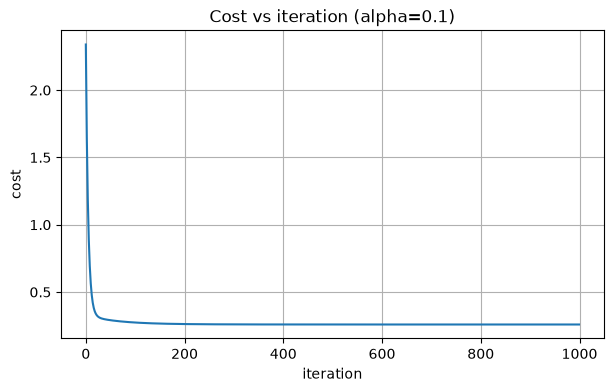

In [10]:
plt.figure(figsize=(7,4))
plt.plot(history)
plt.xlabel("iteration")
plt.ylabel("cost")
plt.title("Cost vs iteration (alpha=0.1)")
plt.grid(True)
plt.savefig("cost-curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_s, y_train)

comparison = pd.DataFrame({
    "feature": data.feature_names,
    "my_w": w,
    "sklearn_w": model.coef_,
})
comparison["diff"] = (comparison["my_w"] - comparison["sklearn_w"]).abs()

print(comparison.round(4))
print("my bias:", round(b, 4), "| sklearn bias:", round(model.intercept_, 4))

      feature    my_w  sklearn_w    diff
0      MedInc  0.8554     0.8544  0.0011
1    HouseAge  0.1228     0.1225  0.0003
2    AveRooms -0.2962    -0.2944  0.0018
3   AveBedrms  0.3407     0.3393  0.0014
4  Population -0.0022    -0.0023  0.0001
5    AveOccup -0.0409    -0.0408  0.0001
6    Latitude -0.8942    -0.8969  0.0027
7   Longitude -0.8672    -0.8698  0.0026
my bias: 2.0719 | sklearn bias: 2.0719


In [12]:
df2 = df.copy()
df2["BedroomRatio"] = df2["AveBedrms"] / df2["AveRooms"]

print(df2.shape)
df2["BedroomRatio"].describe()

(20640, 10)


count    20640.000000
mean         0.213075
std          0.058023
min          0.100000
25%          0.175426
50%          0.203181
75%          0.239834
max          1.000000
Name: BedroomRatio, dtype: float64

In [14]:
X2=df2.drop(columns="MedHouseVal").values
y2=df2["MedHouseVal"].values
X2_train,X2_test,y2_train,y2_test=train_test_split(
    X2,y2,train_size=0.2,random_state=42
)
mu2 = X2_train.mean(axis=0)
sigma2 = X2_train.std(axis=0)
X2_train_s = (X2_train - mu2) / sigma2
X2_test_s = (X2_test - mu2) / sigma2

w2, b2, history2 = gradient_descent(
    X2_train_s, y2_train, np.zeros(X2_train_s.shape[1]), 0.0, alpha=0.1, iters=1000
)
print("end cost:", history2[-1])
print("weights:", w2.round(3))


end cost: 0.2653697253300768
weights: [ 0.829  0.115  0.205 -0.084 -0.    -0.012 -0.864 -0.851  0.263]


In [15]:
def rmse(y_true, y_pred):
    return np.sqrt(((y_true - y_pred) ** 2).mean())

def r2(y_true, y_pred):
    ss_res = ((y_true - y_pred) ** 2).sum()
    ss_tot = ((y_true - y_true.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot

pred_8 = X_test_s @ w + b
pred_9 = X2_test_s @ w2 + b2

print("8 features -> RMSE:", round(rmse(y_test, pred_8), 4), "| R2:", round(r2(y_test, pred_8), 4))
print("9 features -> RMSE:", round(rmse(y2_test, pred_9), 4), "| R2:", round(r2(y2_test, pred_9), 4))

8 features -> RMSE: 0.7457 | R2: 0.5757
9 features -> RMSE: 0.7146 | R2: 0.6155


In [16]:
model2 = LinearRegression()
model2.fit(X2_train_s, y2_train)

names2 = list(data.feature_names) + ["BedroomRatio"]

comparison2 = pd.DataFrame({
    "feature": names2,
    "my_w": w2,
    "sklearn_w": model2.coef_,
})
comparison2["diff"] = (comparison2["my_w"] - comparison2["sklearn_w"]).abs()

print(comparison2.round(4))
print("my bias:", round(b2, 4), "| sklearn bias:", round(model2.intercept_, 4))

pred_sk = model2.predict(X2_test_s)
print("sklearn 9 features -> RMSE:", round(rmse(y2_test, pred_sk), 4), "| R2:", round(r2(y2_test, pred_sk), 4))

        feature    my_w  sklearn_w    diff
0        MedInc  0.8290     0.8237  0.0053
1      HouseAge  0.1147     0.1142  0.0005
2      AveRooms  0.2054     0.2432  0.0378
3     AveBedrms -0.0840    -0.1193  0.0352
4    Population -0.0001    -0.0005  0.0004
5      AveOccup -0.0124    -0.0127  0.0003
6      Latitude -0.8638    -0.8686  0.0047
7     Longitude -0.8510    -0.8556  0.0046
8  BedroomRatio  0.2632     0.2745  0.0112
my bias: 2.0719 | sklearn bias: 2.0719
sklearn 9 features -> RMSE: 0.7148 | R2: 0.6153


In [17]:
w2, b2, history2 = gradient_descent(
    X2_train_s, y2_train, np.zeros(X2_train_s.shape[1]), 0.0, alpha=0.1, iters=10000
)

comparison2["my_w"] = w2
comparison2["diff"] = (comparison2["my_w"] - comparison2["sklearn_w"]).abs()
print(comparison2.round(4))

pred_9 = X2_test_s @ w2 + b2
print("my 9 features -> RMSE:", round(rmse(y2_test, pred_9), 4), "| R2:", round(r2(y2_test, pred_9), 4))

        feature    my_w  sklearn_w  diff
0        MedInc  0.8237     0.8237   0.0
1      HouseAge  0.1142     0.1142   0.0
2      AveRooms  0.2432     0.2432   0.0
3     AveBedrms -0.1193    -0.1193   0.0
4    Population -0.0005    -0.0005   0.0
5      AveOccup -0.0127    -0.0127   0.0
6      Latitude -0.8686    -0.8686   0.0
7     Longitude -0.8556    -0.8556   0.0
8  BedroomRatio  0.2745     0.2745   0.0
my 9 features -> RMSE: 0.7148 | R2: 0.6153


In [18]:
w8, b8, history8 = gradient_descent(
    X_train_s, y_train, np.zeros(X_train_s.shape[1]), 0.0, alpha=0.1, iters=10000
)

pred_8 = X_test_s @ w8 + b8

rmse_8, r2_8 = rmse(y_test, pred_8), r2(y_test, pred_8)
rmse_9, r2_9 = rmse(y2_test, pred_9), r2(y2_test, pred_9)

print("8 features -> RMSE:", round(rmse_8, 4), "| R2:", round(r2_8, 4))
print("9 features -> RMSE:", round(rmse_9, 4), "| R2:", round(r2_9, 4))
print("RMSE improvement:", round(rmse_8 - rmse_9, 4))
print("R2 improvement:  ", round(r2_9 - r2_8, 4))

8 features -> RMSE: 0.7456 | R2: 0.5758
9 features -> RMSE: 0.7148 | R2: 0.6153
RMSE improvement: 0.0308
R2 improvement:   0.0395


In [19]:
for n in [100, 1000, 10000]:
    w_t, b_t, _ = gradient_descent(
        X2_train_s, y2_train, np.zeros(9), 0.0, alpha=0.1, iters=n
    )
    diff = np.abs(w_t - model2.coef_).max()
    print(n, "iterations -> biggest weight difference:", round(diff, 4))

100 iterations -> biggest weight difference: 0.4239
1000 iterations -> biggest weight difference: 0.0378
10000 iterations -> biggest weight difference: 0.0
